
Dataset loaded successfully!
File: C:\Users\Admin/Downloads\Linear_Algebra_Project_300_Records.xlsx
Shape: (300, 14)
  Student_ID Student_Name  Math_T1  Physics_T1  Chemistry_T1  Biology_T1  \
0     STU001  Aarav Patel       95          87            88          93   
1     STU002   Diya Patel       88         100            86          98   
2     STU003  Krish Patel       89          93            97          88   
3     STU004   Mira Patel       60          54            46          52   
4     STU005  Rohan Patel       72          93            76          73   

   Math_T2  Physics_T2  Chemistry_T2  Biology_T2  Term1_Total  Term1_Average  \
0       91         100            86          97          363          90.75   
1      100         100            93          98          372          93.00   
2       94          97           100          83          367          91.75   
3       53          53            47          46          212          53.00   
4       71          88   

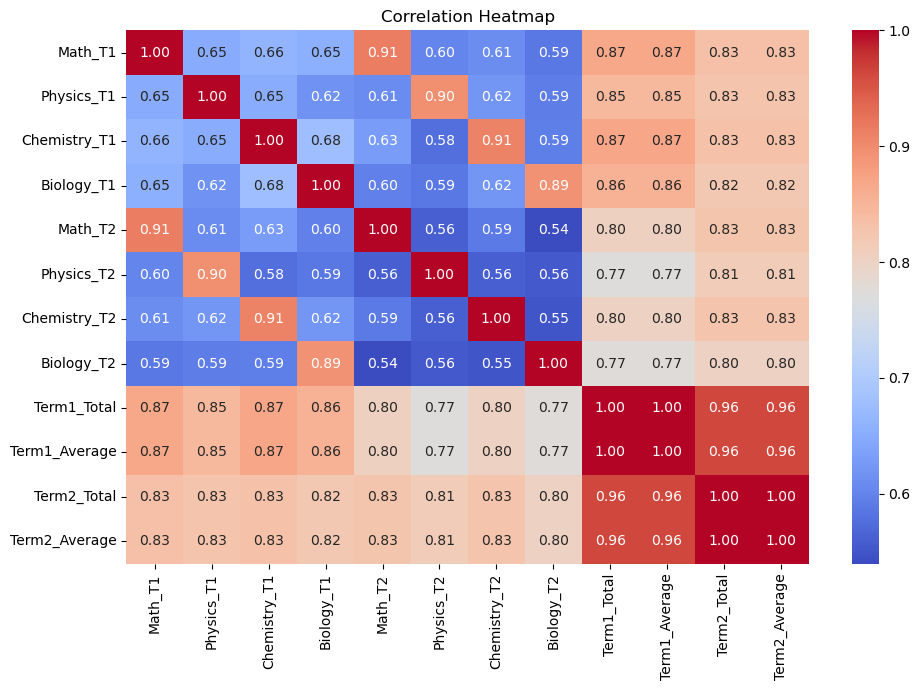

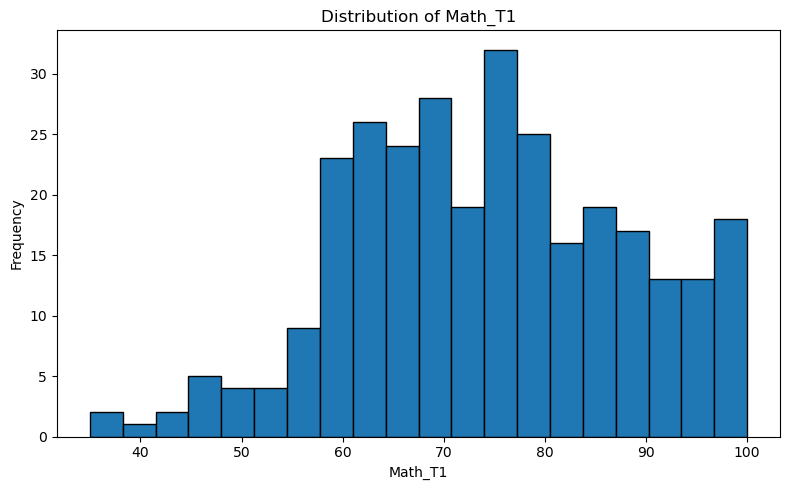

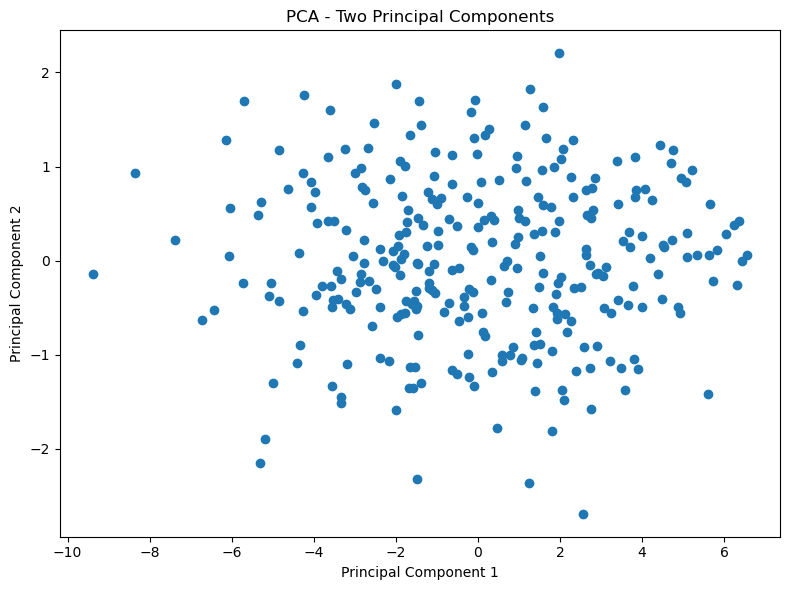


PROJECT COMPLETED SUCCESSFULLY!
Total dataset records: 300
Results saved to: C:\Users\Admin\Linear_Algebra_Analysis_Results.xlsx
Graphs saved in: C:\Users\Admin


In [3]:
# ============================================================
# LINEAR ALGEBRA PROJECT
# 300 STUDENT RECORDS
# Author: Rami Ashutosh
# ============================================================

import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# ============================================================
# 1. FIND OR CREATE EXCEL DATASET
# ============================================================

file_name = "Linear_Algebra_Project_300_Records.xlsx"

# Search current folder and common folders
search_folders = [
    os.getcwd(),
    os.path.expanduser("~/Desktop"),
    os.path.expanduser("~/Downloads"),
    os.path.expanduser("~/Documents"),
    r"C:\Users\Admin\OneDrive\Desktop\Mathematicas"
]

file_path = None

for folder in search_folders:
    if os.path.isdir(folder):
        candidate = os.path.join(folder, file_name)
        if os.path.isfile(candidate):
            file_path = candidate
            break

if file_path is None:
    matches = glob.glob(
        os.path.join(os.getcwd(), "**", "*.xlsx"),
        recursive=True
    )
    matches = [
        path for path in matches
        if not os.path.basename(path).startswith("~$")
    ]

    if matches:
        print("Excel files found:")
        for i, path in enumerate(matches, start=1):
            print(i, path)

        # Prefer the expected project filename if found
        preferred = [
            p for p in matches
            if os.path.basename(p).lower() == file_name.lower()
        ]

        file_path = preferred[0] if preferred else matches[0]

# If no Excel file exists, create a demo dataset
if file_path is None:
    print("Excel file not found. Creating a demo dataset...")

    np.random.seed(42)
    n = 300

    df = pd.DataFrame({
        "Student_ID": range(1001, 1001 + n),
        "Student_Name": [
            f"Student_{i}" for i in range(1, n + 1)
        ],
        "Term1_Maths": np.random.randint(35, 101, n),
        "Term1_Physics": np.random.randint(35, 101, n),
        "Term1_Chemistry": np.random.randint(35, 101, n),
        "Term1_English": np.random.randint(35, 101, n),
        "Term2_Maths": np.random.randint(35, 101, n),
        "Term2_Physics": np.random.randint(35, 101, n),
        "Term2_Chemistry": np.random.randint(35, 101, n),
        "Term2_English": np.random.randint(35, 101, n)
    })

    file_path = os.path.join(os.getcwd(), file_name)
    df.to_excel(file_path, index=False, sheet_name="Dataset")
    print("Demo dataset created:", file_path)

# Load dataset
df = pd.read_excel(file_path, sheet_name=0)

print("\nDataset loaded successfully!")
print("File:", file_path)
print("Shape:", df.shape)
print(df.head())

# ============================================================
# 2. CLEAN NUMERICAL DATA
# ============================================================

numeric_df = df.select_dtypes(include=np.number).copy()

if numeric_df.empty:
    raise ValueError("Dataset has no numerical columns.")

numeric_df = numeric_df.replace([np.inf, -np.inf], np.nan)
numeric_df = numeric_df.fillna(numeric_df.mean())
numeric_df = numeric_df.fillna(0)

A = numeric_df.to_numpy(dtype=float)

print("\nNumerical columns:")
print(numeric_df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

# ============================================================
# 3. VECTOR OPERATIONS
# ============================================================

print("\n" + "=" * 50)
print("VECTOR OPERATIONS")
print("=" * 50)

v1 = A[0]
v2 = A[1] if len(A) > 1 else A[0]

print("Vector 1:", v1)
print("Vector 2:", v2)
print("Vector Addition:", v1 + v2)
print("Vector Subtraction:", v1 - v2)
print("Scalar Multiplication:", 2 * v1)

# ============================================================
# 4. VECTOR NORMS
# ============================================================

l1_norm = np.linalg.norm(v1, ord=1)
l2_norm = np.linalg.norm(v1, ord=2)
infinity_norm = np.linalg.norm(v1, ord=np.inf)

print("\nL1 Norm:", l1_norm)
print("L2 Norm:", l2_norm)
print("Infinity Norm:", infinity_norm)

# ============================================================
# 5. DOT PRODUCT AND ANGLE
# ============================================================

dot_product = np.dot(v1, v2)
denom = np.linalg.norm(v1) * np.linalg.norm(v2)

if denom != 0:
    cosine = np.clip(dot_product / denom, -1, 1)
    angle = np.degrees(np.arccos(cosine))
else:
    angle = np.nan

print("\nDot Product:", dot_product)
print("Angle in degrees:", angle)

# ============================================================
# 6. CROSS PRODUCT
# ============================================================

if len(v1) >= 3:
    cross_product = np.cross(v1[:3], v2[:3])
    print("\nCross Product:", cross_product)
else:
    cross_product = np.array([])
    print("\nCross product requires at least 3 dimensions.")

# ============================================================
# 7. VECTOR PROJECTION
# ============================================================

denom_projection = np.dot(v2, v2)

if denom_projection != 0:
    projection = (np.dot(v1, v2) / denom_projection) * v2
else:
    projection = np.zeros_like(v2)

print("\nProjection of Vector 1 onto Vector 2:")
print(projection)

# ============================================================
# 8. MATRIX OPERATIONS
# ============================================================

print("\n" + "=" * 50)
print("MATRIX OPERATIONS")
print("=" * 50)

rows = min(4, A.shape[0])
cols = min(3, A.shape[1])

matrix_A = A[:rows, :cols]

if A.shape[0] >= 2 * rows:
    matrix_B = A[rows:2 * rows, :cols]
else:
    matrix_B = matrix_A.copy()

matrix_addition = matrix_A + matrix_B
element_multiplication = matrix_A * matrix_B
matrix_transpose = matrix_A.T
matrix_multiplication = matrix_A @ matrix_B.T

print("\nMatrix A:\n", matrix_A)
print("\nMatrix B:\n", matrix_B)
print("\nMatrix Addition:\n", matrix_addition)
print("\nElement-wise Multiplication:\n", element_multiplication)
print("\nTranspose:\n", matrix_transpose)
print("\nMatrix Multiplication:\n", matrix_multiplication)

# ============================================================
# 9. DETERMINANT AND INVERSE
# ============================================================

gram_matrix = matrix_A.T @ matrix_A

determinant = np.linalg.det(gram_matrix)

print("\nGram Matrix:\n", gram_matrix)
print("\nDeterminant:", determinant)

if np.linalg.matrix_rank(gram_matrix) == gram_matrix.shape[0]:
    inverse_matrix = np.linalg.inv(gram_matrix)
    print("\nInverse Matrix:\n", inverse_matrix)
else:
    inverse_matrix = np.linalg.pinv(gram_matrix)
    print("\nMatrix is singular. Pseudo-inverse:\n", inverse_matrix)

# ============================================================
# 10. COVARIANCE MATRIX
# ============================================================

covariance_matrix = np.atleast_2d(
    np.cov(A, rowvar=False)
)

print("\nCovariance Matrix:\n", covariance_matrix)

# ============================================================
# 11. EIGENVALUES AND EIGENVECTORS
# ============================================================

eigenvalues, eigenvectors = np.linalg.eigh(covariance_matrix)

print("\nEigenvalues:\n", eigenvalues)
print("\nEigenvectors:\n", eigenvectors)

# ============================================================
# 12. STANDARDIZATION
# ============================================================

scaler = StandardScaler()
scaled_data = scaler.fit_transform(A)

print("\nStandardized Data (first 5 rows):")
print(scaled_data[:5])

# ============================================================
# 13. PRINCIPAL COMPONENT ANALYSIS
# ============================================================

pca_df = pd.DataFrame()
pca = None

if A.shape[0] >= 2 and A.shape[1] >= 2:
    pca = PCA(n_components=2)
    pca_values = pca.fit_transform(scaled_data)

    pca_df = pd.DataFrame(
        pca_values,
        columns=["Principal_Component_1",
                 "Principal_Component_2"]
    )

    print("\nPCA Results:")
    print(pca_df.head())

    print("\nExplained Variance Ratio:")
    print(pca.explained_variance_ratio_)

    print(
        "Total Variance Explained:",
        pca.explained_variance_ratio_.sum()
    )

# ============================================================
# 14. VISUALIZATIONS
# ============================================================

plt.figure(figsize=(10, 7))
sns.heatmap(
    numeric_df.corr(),
    cmap="coolwarm",
    annot=True,
    fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.savefig("correlation_heatmap.png", dpi=150)
plt.show()

column_name = numeric_df.columns[0]

plt.figure(figsize=(8, 5))
plt.hist(numeric_df[column_name], bins=20, edgecolor="black")
plt.title(f"Distribution of {column_name}")
plt.xlabel(column_name)
plt.ylabel("Frequency")
plt.tight_layout()
plt.savefig("numerical_distribution.png", dpi=150)
plt.show()

if not pca_df.empty:
    plt.figure(figsize=(8, 6))
    plt.scatter(
        pca_df["Principal_Component_1"],
        pca_df["Principal_Component_2"]
    )
    plt.title("PCA - Two Principal Components")
    plt.xlabel("Principal Component 1")
    plt.ylabel("Principal Component 2")
    plt.tight_layout()
    plt.savefig("pca_scatter_plot.png", dpi=150)
    plt.show()

# ============================================================
# 15. EXPORT RESULTS TO EXCEL
# ============================================================

output_file = os.path.join(
    os.getcwd(),
    "Linear_Algebra_Analysis_Results.xlsx"
)

metrics_df = pd.DataFrame({
    "Metric": [
        "L1 Norm",
        "L2 Norm",
        "Infinity Norm",
        "Dot Product",
        "Angle Degrees",
        "Determinant of Gram Matrix"
    ],
    "Value": [
        l1_norm,
        l2_norm,
        infinity_norm,
        dot_product,
        angle,
        determinant
    ]
})

with pd.ExcelWriter(output_file, engine="openpyxl") as writer:
    df.to_excel(
        writer,
        sheet_name="Original_Dataset",
        index=False
    )

    numeric_df.to_excel(
        writer,
        sheet_name="Numerical_Data",
        index=False
    )

    metrics_df.to_excel(
        writer,
        sheet_name="Vector_Metrics",
        index=False
    )

    pd.DataFrame(matrix_addition).to_excel(
        writer,
        sheet_name="Matrix_Addition",
        index=False
    )

    pd.DataFrame(element_multiplication).to_excel(
        writer,
        sheet_name="Element_Multiplication",
        index=False
    )

    pd.DataFrame(matrix_multiplication).to_excel(
        writer,
        sheet_name="Matrix_Multiplication",
        index=False
    )

    pd.DataFrame(gram_matrix).to_excel(
        writer,
        sheet_name="Gram_Matrix",
        index=False
    )

    pd.DataFrame(inverse_matrix).to_excel(
        writer,
        sheet_name="Inverse_or_PseudoInverse",
        index=False
    )

    pd.DataFrame(
        covariance_matrix,
        index=numeric_df.columns,
        columns=numeric_df.columns
    ).to_excel(
        writer,
        sheet_name="Covariance_Matrix"
    )

    pd.DataFrame(
        eigenvectors,
        index=numeric_df.columns
    ).to_excel(
        writer,
        sheet_name="Eigenvectors"
    )

    pd.DataFrame({
        "Eigenvalue": eigenvalues
    }).to_excel(
        writer,
        sheet_name="Eigenvalues",
        index=False
    )

    if not pca_df.empty:
        pca_df.to_excel(
            writer,
            sheet_name="PCA_Results",
            index=False
        )

print("\n" + "=" * 50)
print("PROJECT COMPLETED SUCCESSFULLY!")
print("=" * 50)
print("Total dataset records:", len(df))
print("Results saved to:", output_file)
print("Graphs saved in:", os.getcwd())